In [257]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/Uncleaned_DS_jobs.csv")
df.head(10)

,index,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors
0,0,Sr Data Scientist,$137K-$171K (Glassdoor est.),Description\n\nThe Senior Data Scientist is re...,3.1,Healthfirst\n3.1,"New York, NY","New York, NY",1001 to 5000 employees,1993,Nonprofit Organization,Insurance Carriers,Insurance,Unknown / Non-Applicable,"EmblemHealth, UnitedHealth Group, Aetna"
1,1,Data Scientist,$137K-$171K (Glassdoor est.),"Secure our Nation, Ignite your Future\n\nJoin ...",4.2,ManTech\n4.2,"Chantilly, VA","Herndon, VA",5001 to 10000 employees,1968,Company - Public,Research & Development,Business Services,$1 to $2 billion (USD),-1
2,2,Data Scientist,$137K-$171K (Glassdoor est.),Overview\n\n\nAnalysis Group is one of the lar...,3.8,Analysis Group\n3.8,"Boston, MA","Boston, MA",1001 to 5000 employees,1981,Private Practice / Firm,Consulting,Business Services,$100 to $500 million (USD),-1
3,3,Data Scientist,$137K-$171K (Glassdoor est.),JOB DESCRIPTION:\n\nDo you have a passion for ...,3.5,INFICON\n3.5,"Newton, MA","Bad Ragaz, Switzerland",501 to 1000 employees,2000,Company - Public,Electrical & Electronic Manufacturing,Manufacturing,$100 to $500 million (USD),"MKS Instruments, Pfeiffer Vacuum, Agilent Tech..."
4,4,Data Scientist,$137K-$171K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee"
5,5,Data Scientist,$137K-$171K (Glassdoor est.),About Us:\n\nHeadquartered in beautiful Santa ...,4.2,HG Insights\n4.2,"Santa Barbara, CA","Santa Barbara, CA",51 to 200 employees,2010,Company - Private,Computer Hardware & Software,Information Technology,Unknown / Non-Applicable,-1
6,6,Data Scientist / Machine Learning Expert,$137K-$171K (Glassdoor est.),Posting Title\nData Scientist / Machine Learni...,3.9,Novartis\n3.9,"Cambridge, MA","Basel, Switzerland",10000+ employees,1996,Company - Public,Biotech & Pharmaceuticals,Biotech & Pharmaceuticals,$10+ billion (USD),-1
7,7,Data Scientist,$137K-$171K (Glassdoor est.),Introduction\n\nHave you always wanted to run ...,3.5,iRobot\n3.5,"Bedford, MA","Bedford, MA",1001 to 5000 employees,1990,Company - Public,Consumer Electronics & Appliances Stores,Retail,$1 to $2 billion (USD),-1
8,8,Staff Data Scientist - Analytics,$137K-$171K (Glassdoor est.),Intuit is seeking a Staff Data Scientist to co...,4.4,Intuit - Data\n4.4,"San Diego, CA","Mountain View, CA",5001 to 10000 employees,1983,Company - Public,Computer Hardware & Software,Information Technology,$2 to $5 billion (USD),"Square, PayPal, H&R Block"
9,9,Data Scientist,$137K-$171K (Glassdoor est.),Ready to write the best chapter of your career...,3.6,XSELL Technologies\n3.6,"Chicago, IL","Chicago, IL",51 to 200 employees,2014,Company - Private,Enterprise Software & Network Solutions,Information Technology,Unknown / Non-Applicable,-1


In [258]:
df.describe()

,index,Rating,Founded
count,672.000000,672.000000,672.000000
mean,335.500000,3.518601,1635.529762
std,194.133974,1.410329,756.746640
min,0.000000,-1.000000,-1.000000
25%,167.750000,3.300000,1917.750000
50%,335.500000,3.800000,1995.000000
75%,503.250000,4.300000,2009.000000
max,671.000000,5.000000,2019.000000


We can see some issues already, with the foundation year of some companies having some innacurate values (-1).
But also some supposedly numerical values are not shown as such (like the salary or size)

In [259]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 672 entries, 0 to 671
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   index              672 non-null    int64  
 1   Job Title          672 non-null    object 
 2   Salary Estimate    672 non-null    object 
 3   Job Description    672 non-null    object 
 4   Rating             672 non-null    float64
 5   Company Name       672 non-null    object 
 6   Location           672 non-null    object 
 7   Headquarters       672 non-null    object 
 8   Size               672 non-null    object 
 9   Founded            672 non-null    int64  
 10  Type of ownership  672 non-null    object 
 11  Industry           672 non-null    object 
 12  Sector             672 non-null    object 
 13  Revenue            672 non-null    object 
 14  Competitors        672 non-null    object 
dtypes: float64(1), int64(2), object(12)
memory usage: 78.9+ KB


In [260]:
df.isnull().sum()

index                0
Job Title            0
Salary Estimate      0
Job Description      0
Rating               0
Company Name         0
Location             0
Headquarters         0
Size                 0
Founded              0
Type of ownership    0
Industry             0
Sector               0
Revenue              0
Competitors          0
dtype: int64

In [261]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [262]:
df.duplicated().sum()

np.int64(0)

We don't have no duplicated or NULL values (null values being described by values such as -1)

In [263]:
df["min_sal"] = df["salary_estimate"].str.split("-").str[0]
df["max_sal"] = df["salary_estimate"].str.split("-").str[1]
df["max_sal"] = df["max_sal"].str.split(" ").str[0]

In [264]:
df["company_name"]=df["company_name"].str.split("\n").str[0]

In [265]:
df["job_description"]= df["job_description"].str.replace("\n", " ", regex=False)

Here we made the min_sal and max_sal columns have actual integers and fix the strings

In [266]:
sal_strings=["\$", "K"]
pattern = "|".join(sal_strings)
df["min_sal"]=df["min_sal"].str.replace(pattern, "",case=False, regex=True).astype(int)*1000


In [267]:
df["max_sal"] = df["max_sal"].str.split("(").str[0]
df["max_sal"]=df["max_sal"].str.replace(pattern, "",case=False, regex=True).astype(int)*1000


Made a minimum and maximum salary columns

In [268]:

df["salary_estimated"] = (df["min_sal"] + df["max_sal"])/2 #im taking the midpoint salary in intervals

In [269]:
df["salary_estimated"]=df["salary_estimated"]

Ended up making a numerical salary column


In [270]:
df["competitors"] = df["competitors"].str.replace("-1", "Unknown")

Replacing all the (-1) to a more explanatory value "Unknown"

In [271]:
df.head()

,index,job_title,salary_estimate,job_description,rating,company_name,location,headquarters,size,founded,type_of_ownership,industry,sector,revenue,competitors,min_sal,max_sal,salary_estimated
0,0,Sr Data Scientist,$137K-$171K (Glassdoor est.),Description The Senior Data Scientist is resp...,3.1,Healthfirst,"New York, NY","New York, NY",1001 to 5000 employees,1993,Nonprofit Organization,Insurance Carriers,Insurance,Unknown / Non-Applicable,"EmblemHealth, UnitedHealth Group, Aetna",137000,171000,154000.0
1,1,Data Scientist,$137K-$171K (Glassdoor est.),"Secure our Nation, Ignite your Future Join th...",4.2,ManTech,"Chantilly, VA","Herndon, VA",5001 to 10000 employees,1968,Company - Public,Research & Development,Business Services,$1 to $2 billion (USD),Unknown,137000,171000,154000.0
2,2,Data Scientist,$137K-$171K (Glassdoor est.),Overview Analysis Group is one of the larges...,3.8,Analysis Group,"Boston, MA","Boston, MA",1001 to 5000 employees,1981,Private Practice / Firm,Consulting,Business Services,$100 to $500 million (USD),Unknown,137000,171000,154000.0
3,3,Data Scientist,$137K-$171K (Glassdoor est.),JOB DESCRIPTION: Do you have a passion for Da...,3.5,INFICON,"Newton, MA","Bad Ragaz, Switzerland",501 to 1000 employees,2000,Company - Public,Electrical & Electronic Manufacturing,Manufacturing,$100 to $500 million (USD),"MKS Instruments, Pfeiffer Vacuum, Agilent Tech...",137000,171000,154000.0
4,4,Data Scientist,$137K-$171K (Glassdoor est.),Data Scientist Affinity Solutions / Marketing ...,2.9,Affinity Solutions,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee",137000,171000,154000.0


In [272]:
import re
def revenue_fixer(val):

    text = str(val).lower()

    #THE MISSING VALS CASE
    if (
        "unknown" in text
        or "non-applicable" in text
        or text == "-1"
        or "nan" in text
    ):
        return np.nan

    # THE LESS THAN CASE

    if "less than" in text : 
        nums =  re.findall(r"\d+", text)
        if nums:
            val_num=float(nums[0])
            if "billion" in text :
                return val_num * 1e9 * 0.5 #0.5 here as it states less than "x" value, so i took half of it as a starting point
            if "million" in text:
                return val_num*1e6*0.5
        return np.nan
    
    # THE MORE THAN CASE

    if "+" in text or "over" in text or "more than" in text:
        nums = re.findall(r"\d+", text)
        if nums:
            val_num=float(nums[0])
            if "billion" in text:
                return val_num*1e9
            if "million" in text:
                return val_num*1e6
        return np.nan
    
    # THE IN BETWEEN CASE

    nums = re.findall(r"\d+", text)
    if len(nums)>=2:
        first = float(nums[0])
        second = float(nums[1])
        if "billion" in text:
            return ((first+second)/2)*1e9
        if "million" in text:
            return ((first+second)/2)*1e6
        return np.nan

    #LAST CASE

    elif len(nums) == 1 : 
        return float(nums[0])
        
    return np.nan    



df["rev_test"] = df["revenue"].apply(revenue_fixer)

We just transformed the "Revenue" column into a numerical counterpart ("revenue_num") for the next steps

In [273]:
df = df.rename(columns={"rev_test": "revenue_num"})

In [274]:
df = df.rename(columns={"salary_estimated": "salary_num"})

In [275]:
def seniority_checker(title):
    title = str(title).lower()
    if "lead" in title or "principal" in title or "director" in title:
        return "Lead"
    if "senior" in title:
        return "senior"
    if "junior" in title:
        return "junior"
    else:
        return "Unspecified"
df["seniority"] = df["job_description"].apply(seniority_checker)

Created a seniority column that looks through the description of each job, and classifies it , (useful later on)

In [276]:
avg_salary = df.groupby("seniority")["salary_num"].mean()
print(avg_salary)
seniority_mapping = {
    "junior": 1,
    "Unspecified": 4,
    "senior": 2,
    "Lead": 3,
}

df["seniority_score"] = df["seniority"].map(seniority_mapping)

seniority
Lead           120773.209549
Unspecified    128750.000000
junior         106125.000000
senior         119045.454545
Name: salary_num, dtype: float64


In [277]:
def size_numeric(text):
    if "to" in text:
        nums =  re.findall(r"\d+", text)
        return(int(nums[0])+int(nums[1])/2)
    if "+" in text:
        nums =  re.findall(r"\d+", text)
        return int(nums[0])
    
df["size_num"] = df["size"].apply(size_numeric)

Made a new column "size_num" taking the avg of the number of employees working at X company 

In [278]:
df_backup=pd.read_csv("../data/raw/Uncleaned_DS_jobs.csv")
df_backup.head()
df["sector"] = df_backup["Sector"]

In [279]:
df["sector"]=df["sector"].str.replace("-1", "Unknown")

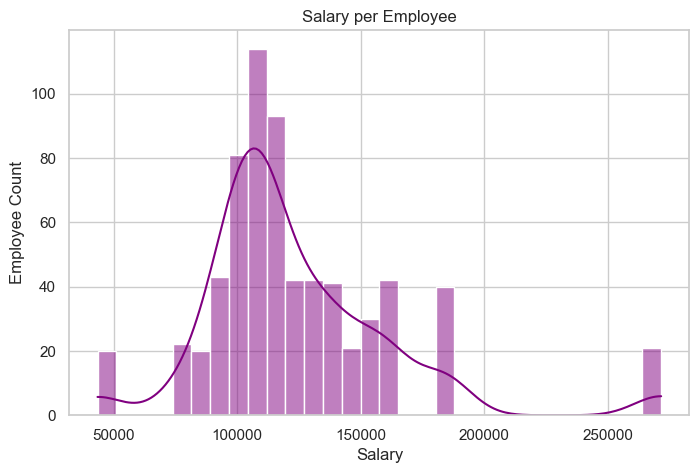

In [280]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(df["salary_num"], bins=30, kde=True, color="purple")
plt.title("Salary per Employee")
plt.xlabel("Salary")
plt.ylabel("Employee Count")

plt.show()

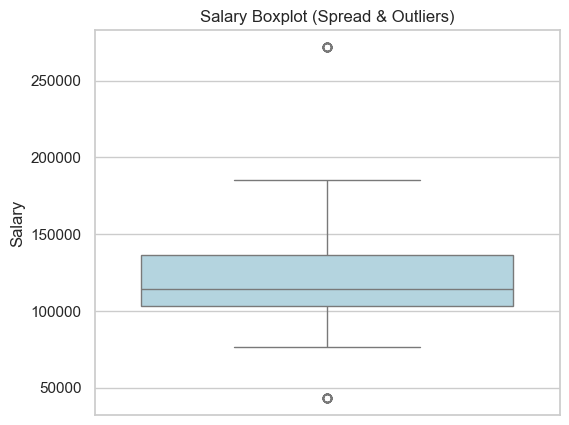

In [281]:
plt.figure(figsize=(6, 5))

sns.boxplot(y=df["salary_num"], color="lightblue")

plt.title("Salary Boxplot (Spread & Outliers)")
plt.ylabel("Salary")
plt.show()

/var/folders/4x/8yhzr1y14ld556ngskgq54000000gn/T/ipykernel_31105/97250751.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


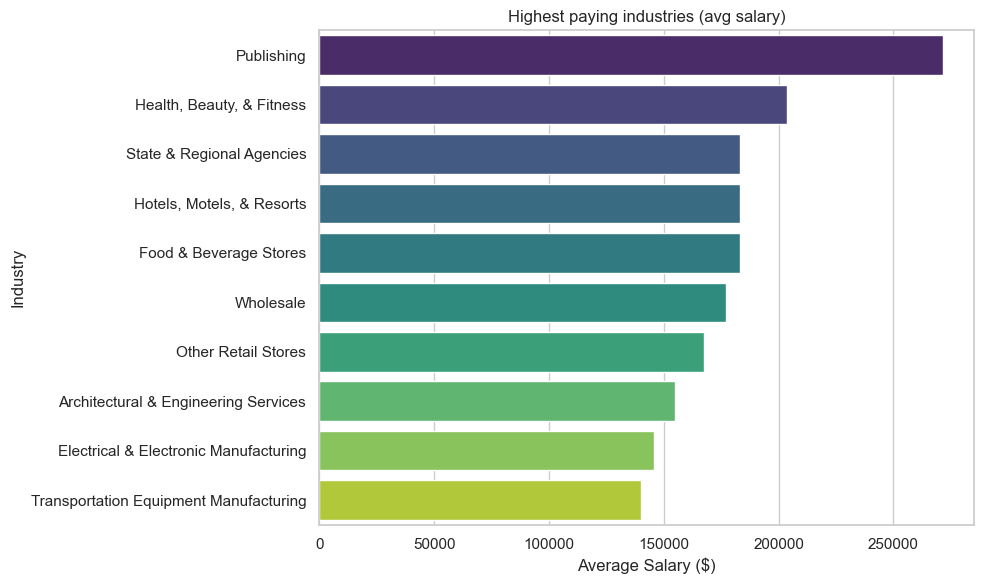

In [282]:
avg_salary_by_industry = (
    df.groupby("industry")["salary_num"].mean().reset_index()
)

avg_salary_by_industry = avg_salary_by_industry.sort_values(
    by="salary_num", ascending=False
).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=avg_salary_by_industry,
    x="salary_num",
    y="industry",
    palette="viridis", 
)

plt.title("Highest paying industries (avg salary)")
plt.xlabel("Average Salary ($)")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

/var/folders/4x/8yhzr1y14ld556ngskgq54000000gn/T/ipykernel_31105/3844043383.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=agg_salary, x="revenue_num", y="salary_num", palette="viridis")


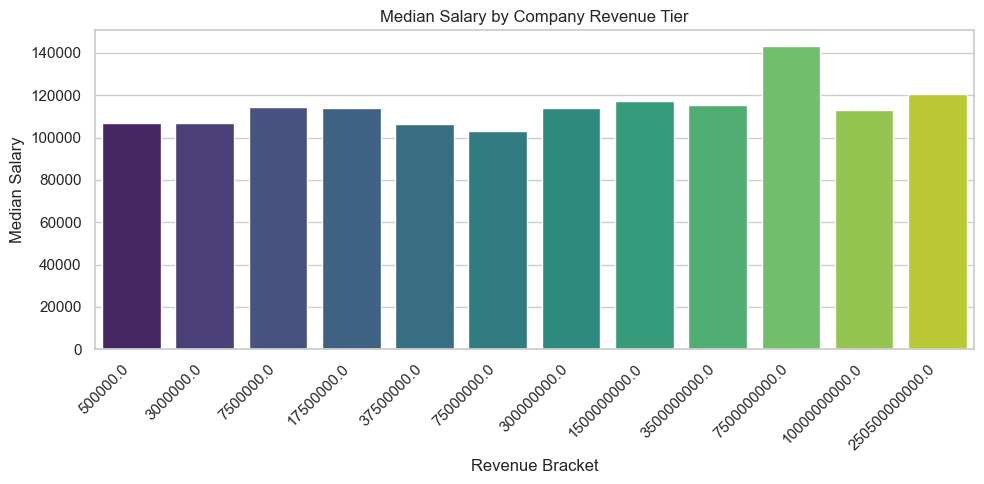

In [283]:

agg_salary = (
    df.groupby("revenue_num")["salary_num"]
    .median()
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(data=agg_salary, x="revenue_num", y="salary_num", palette="viridis")

plt.xticks(rotation=45, ha="right")
plt.title("Median Salary by Company Revenue Tier")
plt.xlabel("Revenue Bracket")
plt.ylabel("Median Salary")
plt.tight_layout()
plt.show()

We can see the relationship of salaries

/var/folders/4x/8yhzr1y14ld556ngskgq54000000gn/T/ipykernel_31105/2268200311.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="seniority", y="salary_num", data=df, palette="Set2")


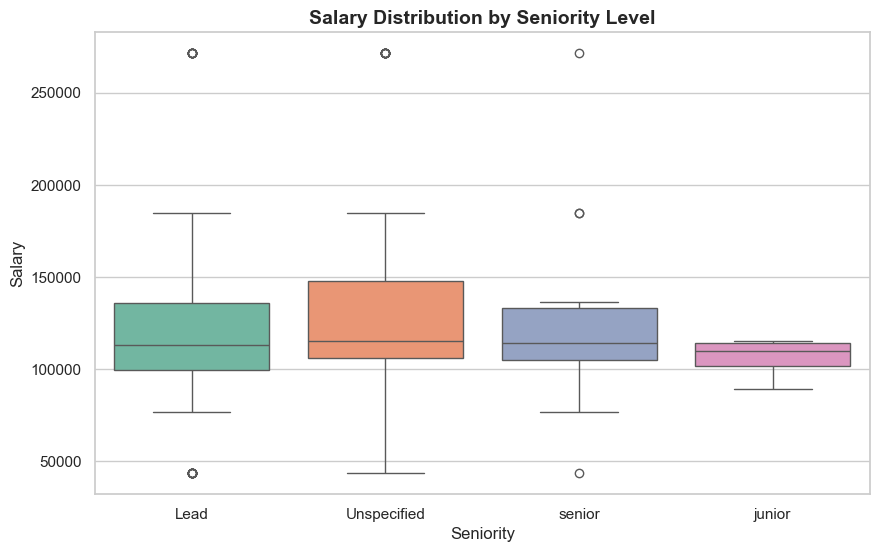

In [284]:
sns.set_theme(style="whitegrid")


plt.figure(figsize=(10, 6))


sns.boxplot(x="seniority", y="salary_num", data=df, palette="Set2")


plt.title("Salary Distribution by Seniority Level", fontsize=14, fontweight="bold")
plt.xlabel("Seniority", fontsize=12)
plt.ylabel("Salary", fontsize=12)

plt.show()

In this dataset, we can see that seniority isn't really impacting the salary as we expect it to. (Most likely due to glassdoor specification for job listings being not too accurate)

In [285]:
df["city"] = df["location"].str.split(",").str[1]

<Axes: xlabel='city'>

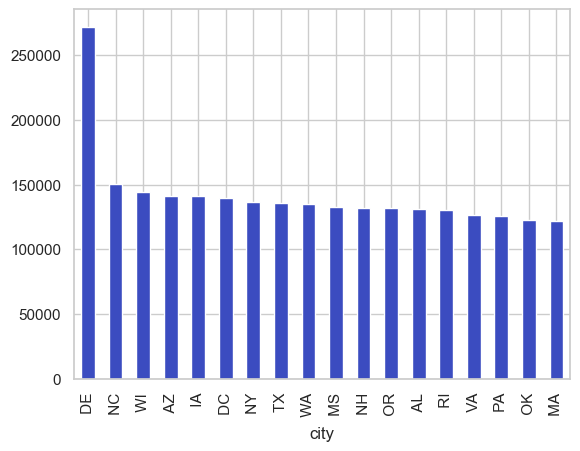

In [286]:
df.groupby("city")["salary_num"].mean().sort_values(ascending=False).head(18).plot(kind="bar", cmap="coolwarm")

In [287]:
df = df.set_index("index")

In [288]:
df["city"].nunique()

39

In [289]:
df["city_num"] = df["city"].map(df["city"].value_counts())

Frequency encoding for the cities to obtain a numerical column 

In [293]:
df.head()

,job_title,salary_estimate,job_description,rating,company_name,location,headquarters,size,founded,type_of_ownership,...,competitors,min_sal,max_sal,salary_num,revenue_num,seniority,seniority_score,size_num,city,city_num
index,,,,,,,,,,,,,,,,,,,,,
0,Sr Data Scientist,$137K-$171K (Glassdoor est.),Description The Senior Data Scientist is resp...,3.1,Healthfirst,"New York, NY","New York, NY",1001 to 5000 employees,1993,Nonprofit Organization,...,"EmblemHealth, UnitedHealth Group, Aetna",137000,171000,154000.0,NaN,Lead,3,3501.0,NY,52.0
1,Data Scientist,$137K-$171K (Glassdoor est.),"Secure our Nation, Ignite your Future Join th...",4.2,ManTech,"Chantilly, VA","Herndon, VA",5001 to 10000 employees,1968,Company - Public,...,Unknown,137000,171000,154000.0,1.500000e+09,Unspecified,4,10001.0,VA,89.0
2,Data Scientist,$137K-$171K (Glassdoor est.),Overview Analysis Group is one of the larges...,3.8,Analysis Group,"Boston, MA","Boston, MA",1001 to 5000 employees,1981,Private Practice / Firm,...,Unknown,137000,171000,154000.0,3.000000e+08,Lead,3,3501.0,MA,62.0
3,Data Scientist,$137K-$171K (Glassdoor est.),JOB DESCRIPTION: Do you have a passion for Da...,3.5,INFICON,"Newton, MA","Bad Ragaz, Switzerland",501 to 1000 employees,2000,Company - Public,...,"MKS Instruments, Pfeiffer Vacuum, Agilent Tech...",137000,171000,154000.0,3.000000e+08,Unspecified,4,1001.0,MA,62.0
4,Data Scientist,$137K-$171K (Glassdoor est.),Data Scientist Affinity Solutions / Marketing ...,2.9,Affinity Solutions,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,...,"Commerce Signals, Cardlytics, Yodlee",137000,171000,154000.0,NaN,Lead,3,151.0,NY,52.0
